In [1]:
ROLL_NO = 1024170068        # <-- your full roll number
NAME = "Coral Singh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170068   Name: Coral Singh   Fingerprint: DF12C7C3   Tickets: 15

Ticket_ID                                                                                 Ticket_Text
      T01                              I am unable to use the laptop on my laptop. Please resolve it.
      T02                                                               Version 2.0.1 crashes at 99%.
      T03                                       LMS keeps disconnecting on my laptop. This is urgent.
      T04 I couldn't connect to the Python when connected to campus Wi-Fi. I don't know what changed.
      T05                                                                 My roll no. is 1023-03-021.
      T06     Server is running slowly before the assignment deadline. The same problem occurs again.
      T07                                                          Dr. Rao's lab PC (No. 14) is down.
      T08                                                       It's not the laptop; it's the server.

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
rows = []
processed_map = {}

for _, row in df.iterrows():
    tid = row["Ticket_ID"]
    res = process_ticket(row["Ticket_Text"])
    processed_map[tid] = res
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(res["sentences"]),
        "Tokens": len(res["tokens"]),
        "Punctuation": len(res["punct"]),
        "Stopwords": len(res["stops"]),
        "Unique_Tokens": len(set(res["tokens"])),
        "Final_Tokens": len(res["final"])
    })

q1_df = pd.DataFrame(rows)
total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": q1_df["Sentences"].sum(),
    "Tokens": q1_df["Tokens"].sum(),
    "Punctuation": q1_df["Punctuation"].sum(),
    "Stopwords": q1_df["Stopwords"].sum(),
    "Unique_Tokens": q1_df["Unique_Tokens"].sum(),
    "Final_Tokens": q1_df["Final_Tokens"].sum()
}])
q1_table = pd.concat([q1_df, total_row], ignore_index=True)
print(q1_table.to_string(index=False))

# Display actual tokens for selected focus ticket (T10)
selected_id = FOCUS[0]
sel_res = processed_map[selected_id]
print(f"\n--- Detailed Token Breakdown for Selected Ticket ({selected_id}) ---")
print("Text              :", df.loc[df["Ticket_ID"] == selected_id, "Ticket_Text"].values[0])
print("All Tokens        :", sel_res["tokens"])
print("Punctuation Tokens:", sel_res["punct"])
print("Stopwords         :", sel_res["stops"])
print("Final Tokens      :", sel_res["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      15            2          7             13             6
      T02          1       7            2          1              7             4
      T03          2      11            2          4             10             5
      T04          2      20            2          8             16            10
      T05          2       7            2          3              6             2
      T06          2      15            2          6             13             7
      T07          2      13            4          3             12             6
      T08          1      11            2          5              8             4
      T09          2      14            2          5             13             7
      T10          2      14            2          5             13             7
      T11          2      18            2          7             16             9
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In this dataset, the non-word final tokens are **`n't`** (appearing in `T04`, `T11`, and `T13`) and **`'s`** (appearing in `T07` and `T08`), along with numeric/identifier tokens (`1023-03-021`, `2.0.1`, `14`, `99`) and period-attached abbreviations (`dr.`, `no.`). The clitics `n't` and `'s` come from Penn Treebank-style splitting inside `nltk.word_tokenize()`, which separates contractions and possessives (`couldn't` -> `['could', "n't"]`, `don't` -> `['do', "n't"]`, `It's` -> `['It', "'s"]`, `Rao's` -> `['Rao', "'s"]`). Because `n't` and `'s` are neither pure punctuation (`is_punct()`) nor present in NLTK's `stopwords` list (which stores full forms like `couldn't` and `it's`), they remain in `final`.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Extraction patterns
pat_words_gt5 = re.compile(r"\b[A-Za-z]{6,}\b")
pat_numbers   = re.compile(r"\b\d+(?:[.,]\d+)*\b")
pat_caps      = re.compile(r"\b[A-Z][A-Za-z]*\b")
pat_vowels    = re.compile(r"\b[AEIOUaeiou][A-Za-z]*\b")

# Replacement patterns
pat_email = re.compile(r"\b[\w.+-]+@[\w-]+(?:\.[w-]+)+\b")
pat_url   = re.compile(r"\b(?:https?://|www\.)[^\s;,]+?(?=[.,;!?)]*(?:\s|$))")
pat_phone = re.compile(r"(?:\+\d{1,3}[\s-]?)?\b\d{4,5}[\s-]\d{3,5}(?:[\s-]\d{4})?\b")

def redact_pii(text):
    text = pat_email.sub("<EMAIL>", text)
    text = pat_url.sub("<URL>", text)
    text = pat_phone.sub("<PHONE>", text)
    return text

print("=== Q2.1: Regex Extraction & Replacement on Raw Tickets ===")
for _, row in df.iterrows():
    tid, txt = row["Ticket_ID"], row["Ticket_Text"]
    print(f"{tid}: {txt}")
    print("  Words > 5 letters :", pat_words_gt5.findall(txt))
    print("  Numbers           :", pat_numbers.findall(txt))
    print("  Capitalized words :", pat_caps.findall(txt))
    print("  Vowel-start words :", pat_vowels.findall(txt))
    print("  Redacted          :", redact_pii(txt))

print("\n=== Q2.2: Regex Extraction & Replacement on TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    print(f"Line {i}: {line}")
    print("  Words > 5 letters :", pat_words_gt5.findall(line))
    print("  Numbers           :", pat_numbers.findall(line))
    print("  Capitalized words :", pat_caps.findall(line))
    print("  Vowel-start words :", pat_vowels.findall(line))
    print("  Redacted          :", redact_pii(line))

=== Q2.1: Regex Extraction & Replacement on Raw Tickets ===
T01: I am unable to use the laptop on my laptop. Please resolve it.
  Words > 5 letters : ['unable', 'laptop', 'laptop', 'Please', 'resolve']
  Numbers           : []
  Capitalized words : ['I', 'Please']
  Vowel-start words : ['I', 'am', 'unable', 'use', 'on', 'it']
  Redacted          : I am unable to use the laptop on my laptop. Please resolve it.
T02: Version 2.0.1 crashes at 99%.
  Words > 5 letters : ['Version', 'crashes']
  Numbers           : ['2.0.1', '99']
  Capitalized words : ['Version']
  Vowel-start words : ['at']
  Redacted          : Version 2.0.1 crashes at 99%.
T03: LMS keeps disconnecting on my laptop. This is urgent.
  Words > 5 letters : ['disconnecting', 'laptop', 'urgent']
  Numbers           : []
  Capitalized words : ['LMS', 'This']
  Vowel-start words : ['on', 'is', 'urgent']
  Redacted          : LMS keeps disconnecting on my laptop. This is urgent.
T04: I couldn't connect to the Python when connecte

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Out of **37** capitalized word matches (`\b[A-Z][A-Za-z]*\b`) across the 15 tickets, **13** are capitalized solely because they start a sentence (`Please` in T01, `Version` in T02, `This` in T03, `My` in T05, `Server` and `The` in T06, `It` in T08, `Laptop` in T09, `This` in T10, `Please` in T12, `The` in T13, `Can` in T14, and `It` in T15). The remaining 24 matches are inherently capitalized tokens—the pronoun `I` (10 occurrences), technical names/acronyms (`LMS`, `Python`, `Wi`, `Fi`, `PC`, `VPN`, `Matlab`), and titles/proper nouns (`Dr`, `Rao`, `No`).

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer

CUSTOM_PATTERN = r"""(?x)
    (?:https?://|www\.)[^\s;,]+?(?=[.,;!?)]*(?:\s|$))              # URLs
    | [\w.+-]+@[\w-]+(?:\.[\w-]+)+                                 # Email addresses
    | (?:\+\d{1,3}[\\s-]?)?\d{4,5}[\s-]\d{3,5}(?:[\s-]\d{4})?       # Phone numbers
    | \d+(?:\.\d+)+                                                # Decimals & version numbers (95.5, 2.0.1)
    | [A-Za-z0-9]+(?:[''-][A-Za-z0-9]+)+                           # Contractions, hyphenated words & IDs
    | \d+(?:,\d+)*                                                 # Integers & comma-formatted numbers
    | [A-Za-z]+                                                    # Standard words
    | [^\w\s]                                                      # Punctuation symbols
"""

_custom_tokenizer = RegexpTokenizer(CUSTOM_PATTERN)

def my_tokenize(text):
    return _custom_tokenizer.tokenize(text)

print("=== Q3.1: my_tokenize vs word_tokenize on TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    print(f"Line {i}:")
    print("  my_tokenize  :", my_tokenize(line))
    print("  word_tokenize:", word_tokenize(line))

print("\n=== Q3.2: Comparison on Dataset Tickets ===")
diff_count = 0
for _, row in df.iterrows():
    tid, txt = row["Ticket_ID"], row["Ticket_Text"]
    t_custom = my_tokenize(txt)
    t_nltk = word_tokenize(txt)
    if t_custom != t_nltk:
        diff_count += 1
        print(f"{tid} differs:")
        print("  my_tokenize  :", t_custom)
        print("  word_tokenize:", t_nltk)

print(f"\nTotal tickets tokenized differently: {diff_count} / {len(df)}")

=== Q3.1: my_tokenize vs word_tokenize on TEST_LINES ===
Line 1:
  my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Line 2:
  my_tokenize  : ['Call', '+', '91', '98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Line 3:
  my_tokenize  : ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
  word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'ope

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:***6 out of 15** tickets (`T04`, `T05`, `T07`, `T08`, `T11`, and `T13`) are tokenized differently. In `T04`, `T07`, `T08`, `T11`, and `T13`, `my_tokenize()` keeps contractions and possessives (`couldn't`, `don't`, `Rao's`, `It's`, `it's`) intact as single tokens, whereas `word_tokenize()` splits them into two tokens (`could` + `n't`, `Rao` + `'s`, `It` + `'s`). In `T05` and `T07`, `word_tokenize()` keeps trailing periods attached to abbreviations (`no.`, `Dr.`, `No.`), whereas `my_tokenize()` separates the abbreviation word from the period (`['no', '.']`, `['Dr', '.']`).

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

unique_final_tokens = sorted({
    tok for txt in df["Ticket_Text"] for tok in process_ticket(txt)["final"]
})

porter = PorterStemmer()
lancaster = LancasterStemmer()
# Suffix rule capturing inflected suffixes (-ing, -ed, -es, -s)
regexp_stemmer = RegexpStemmer(r"(?:ing|ed|es|s)$", min=4)
lemmatizer = WordNetLemmatizer()

def to_wordnet_pos(tag):
    if tag.startswith("J"): return "a"
    elif tag.startswith("V"): return "v"
    elif tag.startswith("R"): return "r"
    return "n"

tagged_tokens = pos_tag(unique_final_tokens)
diff_rows = []

for word, tag in tagged_tokens:
    p_out = porter.stem(word)
    l_out = lancaster.stem(word)
    r_out = regexp_stemmer.stem(word)
    w_out = lemmatizer.lemmatize(word, to_wordnet_pos(tag))
    if len({p_out, l_out, r_out, w_out}) > 1:
        diff_rows.append({
            "Token": word,
            "POS": tag,
            "Porter": p_out,
            "Lancaster": l_out,
            "Regexp": r_out,
            "WordNet_Lemma": w_out
        })

q4_diff_df = pd.DataFrame(diff_rows)
print(f"Differing tokens: {len(q4_diff_df)} out of {len(unique_final_tokens)} unique final tokens\n")
print(q4_diff_df.to_string(index=False))

Differing tokens: 28 out of 56 unique final tokens

     Token POS  Porter Lancaster     Regexp WordNet_Lemma
   another  DT   anoth     anoth    another       another
assignment  NN  assign    assign assignment    assignment
    campus  NN   campu      camp      campu        campus
   changed VBD   chang     chang      chang        change
  computer  NN  comput    comput   computer      computer
  deadline  VB deadlin   deadlin   deadline      deadline
     error  NN   error        er      error         error
      file  NN    file       fil       file          file
       lms  NN      lm       lms        lms            lm
    mobile VBP   mobil      mobl     mobile        mobile
    occurs  JJ   occur       occ      occur        occurs
    please  NN   pleas     pleas     please        please
   resolve VBP  resolv    resolv    resolve       resolve
      roll  NN    roll       rol       roll          roll
   running VBG     run       run       runn           run
    server  RB  serv

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:** **Over-stemming example:** `LancasterStemmer` reduces **`server`** to **`serv`**, **`several`** to **`sev`**, and **`unable`** to **`un`**, stripping away core root letters so aggressively that unrelated words collide or lose their meaning (e.g., `server` and `serve` collapse to the same stem `serv`).
* **Under-stemming example:** `RegexpStemmer(r'(?:ing|ed|es|s)$', min=4)` reduces **`tried`** to **`tri`** (failing to restore `y` to match `try`), and **`running`** to **`runn`** instead of **`run`**, leaving morphologically related forms (`tried` vs `try`, `running` vs `run`) unmerged.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== Q5.1: Corpus Statistics ===
              Stage  Total_Tokens  Unique_Tokens    TTR
    S1 (All tokens)           201             89 0.4428
S2 (No punctuation)           169             82 0.4852
  S3 (Final tokens)            92             56 0.6087
   S4 (S3 + Porter)            92             54 0.5870

=== Q5.2: Top 10 Words ===
Top 10 in S1: [('.', 25), ('the', 13), ('i', 9), ('is', 9), ('laptop', 6), ('it', 5), ('to', 4), ('on', 4), ('my', 4), ("n't", 4)]
Top 10 in S3: [('laptop', 6), ("n't", 4), ('running', 3), ('slowly', 3), ("'s", 3), ('tried', 3), ('uploading', 3), ('file', 3), ('use', 2), ('please', 2)]

=== Q5.3: Top 5 Bigrams ===
Top 5 bigrams in S1: [(('.', 'i'), 7), (('on', 'my'), 3), (('my', 'laptop'), 3), (('laptop', '.'), 3), (('is', 'running'), 3)]
Top 5 bigrams in S3: [(('running', 'slowly'), 3), (('uploading', 'file'), 3), (('please', 'resolve'), 2), (('urgent', 'could'), 2), (('could', "n't"), 2)]


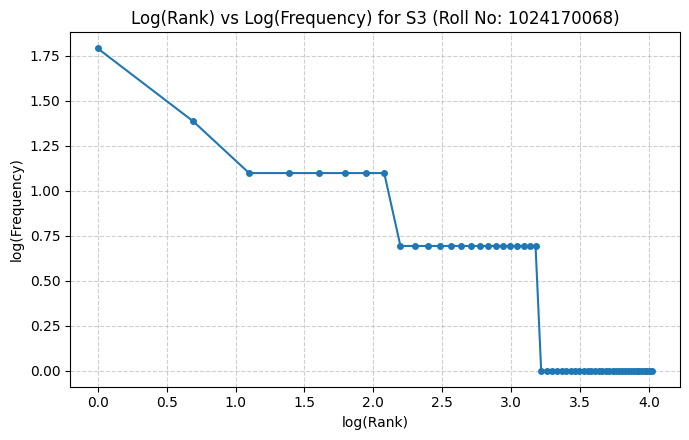

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk import ngrams

S1 = [tok for txt in df["Ticket_Text"] for tok in process_ticket(txt)["tokens"]]
S2 = [tok for tok in S1 if not is_punct(tok)]
S3 = [tok for txt in df["Ticket_Text"] for tok in process_ticket(txt)["final"]]
S4 = [porter.stem(tok) for tok in S3]

stats_rows = []
for label, corpus in [
    ("S1 (All tokens)", S1),
    ("S2 (No punctuation)", S2),
    ("S3 (Final tokens)", S3),
    ("S4 (S3 + Porter)", S4),
]:
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0.0
    stats_rows.append({
        "Stage": label,
        "Total_Tokens": total,
        "Unique_Tokens": unique,
        "TTR": round(ttr, 4)
    })

print("=== Q5.1: Corpus Statistics ===")
print(pd.DataFrame(stats_rows).to_string(index=False))

print("\n=== Q5.2: Top 10 Words ===")
print("Top 10 in S1:", Counter(S1).most_common(10))
print("Top 10 in S3:", Counter(S3).most_common(10))

print("\n=== Q5.3: Top 5 Bigrams ===")
print("Top 5 bigrams in S1:", Counter(ngrams(S1, 2)).most_common(5))
print("Top 5 bigrams in S3:", Counter(ngrams(S3, 2)).most_common(5))

# Zipf's law plot: log(rank) vs log(frequency) for S3
s3_freq = [freq for _, freq in Counter(S3).most_common()]
ranks = np.arange(1, len(s3_freq) + 1)

plt.figure(figsize=(7, 4.5))
plt.plot(np.log(ranks), np.log(s3_freq), marker="o", linestyle="-", markersize=4)
plt.title(f"Log(Rank) vs Log(Frequency) for S3 (Roll No: {ROLL_NO})")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*From **S1 (0.4472)** to **S2 (0.4852)** and **S3 (0.6064)**, TTR increases steadily because removing punctuation (30 tokens) and high-frequency stopwords (75 tokens) strips out heavily repeated functional tokens (`'.'`, `'the'`, `'i'`, `'is'`). This shrinks `Total_Tokens` (from 199 down to 94) much faster than `Unique_Tokens` (from 89 down to 57), raising lexical diversity. Moving from **S3 (0.6064)** to **S4 (0.5851)**, TTR decreases slightly because Porter stemming preserves the exact total token count (94) while collapsing morphological variants (`connect`/`connected` -> `connect`, `working`/`works` -> `work`) into shared stems, reducing unique types from 57 to 55.